# Dự án cuối kỳ Học Máy: Xây dựng Mô hình Dự đoán Sinh viên Thôi học sớm (OULAD)

**Mô tả:** Dự đoán sớm (tại các mốc D=30, 60, 90 ngày kể từ ngày bắt đầu học phần) liệu một sinh viên
có thôi học (Withdrawn) hay không, chỉ dùng thông tin có trong cửa sổ [0, D].

**Phạm vi (bám sát slide môn học):** KNN, Naive Bayes, Cây quyết định, SVM tuyến tính, Rừng ngẫu nhiên;
PCA (giảm chiều) và K-Means (phân cụm, chọn k bằng quy tắc khuỷu tay). Không dùng deep learning.

**Quy trình (theo chương 2):** tách train/test theo sinh viên → tiền xử lý → chọn tham số bằng cross-validation
(GridSearchCV, tiêu chí F1) chỉ trên tập train → đánh giá trên tập test đúng một lần → phân tích lỗi.

**Bộ dữ liệu:** Open University Learning Analytics Dataset (OULAD), UCI ML Repository.

**Chỉ số:** confusion matrix, accuracy, precision, recall, F1; so sánh với 2 mô hình nền (đoán không ai thôi học /
đoán tất cả thôi học).

## 1. Thiết lập môi trường và tải dữ liệu

Cell dưới đây tự tải dữ liệu từ UCI (chạy được trên Google Colab). Nếu dữ liệu đã có sẵn thì bỏ qua.

In [2]:
import os
import json
import zipfile
import urllib.request
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

# --- Cấu hình chung (chỉnh ở đây) ---
SEED = 42
DEPLOY_D = 30          # mốc D dùng để triển khai (cảnh báo sớm nhất)
CV_FOLDS = 3           # số fold của cross-validation
PHAN_VI = (0.70, 0.90) # chia mức rủi ro: 70% thấp nhất = Thấp, 70-90% = Trung bình, 10% cao nhất = Cao

# --- Các đường dẫn ---
BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, "dataset")
ART_DIR = os.path.join(BASE_DIR, "artifacts")
CACHE_DIR = os.path.join(ART_DIR, "cache")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(ART_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

URL = "https://archive.ics.uci.edu/static/public/349/open%2Buniversity%2Blearning%2Banalytics%2Bdataset.zip"

def tai_du_lieu():
    """Tải và giải nén OULAD nếu chưa có."""
    csv_can_thiet = ["studentInfo.csv", "studentRegistration.csv", "assessments.csv",
                     "studentAssessment.csv", "studentVle.csv", "vle.csv", "courses.csv"]
    if all(os.path.exists(os.path.join(DATA_DIR, f)) for f in csv_can_thiet):
        print("[OK] Dữ liệu đã có sẵn tại", DATA_DIR)
        return
    print("[*] Đang tải dữ liệu OULAD từ UCI...")
    zip_path = os.path.join(BASE_DIR, "data", "oulad.zip")
    os.makedirs(os.path.dirname(zip_path), exist_ok=True)
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(DATA_DIR)
    print("[OK] Đã giải nén dữ liệu.")

tai_du_lieu()

[OK] Dữ liệu đã có sẵn tại e:\CaNhan\VoNhatHuy_Namba\HOCMAY\Machine learning\FINALEX\dataset


## 2. Đọc và tiền xử lý thô các bảng dữ liệu

`studentVle.csv` rất lớn (~10.6M dòng). Chúng ta chỉ cần hoạt động trong cửa sổ [0, 90] ngày,
nên lọc ngay từ lúc đọc theo chunk để tiết kiệm bộ nhớ.

In [3]:
print("[*] Đọc các bảng nhỏ...")
courses = pd.read_csv(os.path.join(DATA_DIR, "courses.csv"))
assessments = pd.read_csv(os.path.join(DATA_DIR, "assessments.csv"),
                          dtype={"code_module": "category", "code_presentation": "category"})
studentInfo = pd.read_csv(os.path.join(DATA_DIR, "studentInfo.csv"),
                          dtype={"code_module": "category", "code_presentation": "category",
                                 "gender": "category", "region": "category",
                                 "highest_education": "category", "imd_band": "category",
                                 "age_band": "category", "disability": "category",
                                 "final_result": "category"})
studentRegistration = pd.read_csv(os.path.join(DATA_DIR, "studentRegistration.csv"))
studentAssessment = pd.read_csv(os.path.join(DATA_DIR, "studentAssessment.csv"))
vle = pd.read_csv(os.path.join(DATA_DIR, "vle.csv"),
                  dtype={"code_module": "category", "code_presentation": "category",
                         "activity_type": "category"})

assessments["date"] = pd.to_numeric(assessments["date"], errors="coerce")
studentAssessment["score"] = pd.to_numeric(studentAssessment["score"], errors="coerce")
studentAssessment["date_submitted"] = pd.to_numeric(studentAssessment["date_submitted"], errors="coerce")
studentRegistration["date_registration"] = pd.to_numeric(studentRegistration["date_registration"], errors="coerce")
studentRegistration["date_unregistration"] = pd.to_numeric(studentRegistration["date_unregistration"], errors="coerce")

KEYS = ["code_module", "code_presentation", "id_student"]
print(f"[OK] studentInfo: {len(studentInfo)} dòng (mỗi dòng = 1 sinh viên trong 1 học phần)")

[*] Đọc các bảng nhỏ...
[OK] studentInfo: 32593 dòng (mỗi dòng = 1 sinh viên trong 1 học phần)


### 2.1 Xử lý bảng `studentVle` (clickstream)

Đọc theo từng chunk, chỉ giữ lại các bản ghi có `0 <= date <= 90`.
Giữ lại cả `activity_type` gốc để xây dựng đặc trưng engagement theo loại hoạt động.

In [4]:
NHOM_HOAT_DONG = {
    "forumng": "forum",
    "quiz": "quiz", "externalquiz": "quiz", "questionnaire": "quiz",
    "resource": "content", "oucontent": "content", "page": "content",
    "subpage": "content", "url": "content", "folder": "content",
    "glossary": "content", "dataplus": "content", "htmlactivity": "content",
    "repeatactivity": "content", "dualpane": "content", "sharedsubpage": "content",
    "homepage": "content", "ouwiki": "content",
    "oucollaborate": "collab", "workshop": "collab", "imcitutorial": "collab",
    "ouelluminate": "collab",
}
vle["nhom_hoat_dong"] = vle["activity_type"].astype(str).map(NHOM_HOAT_DONG).fillna("other")
site_to_nhom = dict(zip(vle["id_site"], vle["nhom_hoat_dong"]))
site_to_activity = dict(zip(vle["id_site"], vle["activity_type"].astype(str)))

# 16 loại hoạt động phổ biến nhất (theo số site), còn lại gom vào other_activity
ACTIVITY_TYPES = ["resource", "subpage", "oucontent", "url", "forumng", "quiz", "page",
                  "oucollaborate", "questionnaire", "ouwiki", "dataplus", "externalquiz",
                  "homepage", "glossary", "ouelluminate", "dualpane"]

print("[*] Đọc studentVle theo chunk, lọc 0 <= date <= 90...")
chunks = []
for chunk in pd.read_csv(os.path.join(DATA_DIR, "studentVle.csv"), chunksize=2_000_000,
                         dtype={"code_module": "category", "code_presentation": "category",
                                "id_student": "int32", "id_site": "int32",
                                "sum_click": "int32"}):
    chunk["date"] = pd.to_numeric(chunk["date"], errors="coerce")
    chunk = chunk[(chunk["date"] >= 0) & (chunk["date"] <= 90)]
    chunk["nhom_hoat_dong"] = chunk["id_site"].map(site_to_nhom).fillna("other")
    chunk["activity_type"] = chunk["id_site"].map(site_to_activity).fillna("other")
    chunks.append(chunk[["code_module", "code_presentation", "id_student", "id_site",
                         "date", "sum_click", "nhom_hoat_dong", "activity_type"]])
vle_small = pd.concat(chunks, ignore_index=True)
del chunks
print(f"[OK] Sau lọc cửa sổ [0,90]: {len(vle_small):,} dòng (giảm từ ~10.6M)")

[*] Đọc studentVle theo chunk, lọc 0 <= date <= 90...
[OK] Sau lọc cửa sổ [0,90]: 4,797,890 dòng (giảm từ ~10.6M)


## 3. Xây dựng bộ dữ liệu theo từng mốc thời gian D = 30, 60, 90 ngày

**Cohort tại mốc D:** chỉ giữ sinh viên vẫn còn đăng ký tại ngày D
(`date_unregistration` là NaN HOẶC > D).
**Nhãn:** y=1 nếu `final_result == 'Withdrawn'`, ngược lại y=0.

In [5]:
def imd_to_ord(x):
    if pd.isna(x) or str(x).strip() == "?":
        return np.nan
    s = str(x).strip()
    first = int(s.split("-")[0].replace("%", ""))
    return first // 10

studentInfo["imd_band_ord"] = studentInfo["imd_band"].astype(str).map(imd_to_ord)
studentInfo["age_band_ord"] = studentInfo["age_band"].map({"0-35": 0, "35-55": 1, "55<=": 2})
studentInfo["highest_education_ord"] = studentInfo["highest_education"].map({
    "No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2,
    "HE Qualification": 3, "Post Graduate Qualification": 4})

COT_DEMO_SO = ["num_of_prev_attempts", "studied_credits", "date_registration",
               "imd_band_ord", "age_band_ord", "highest_education_ord", "late_registration"]
COT_ASSESS = ["n_assessments_due", "n_submitted", "submission_rate", "score_mean",
              "score_max", "score_min", "n_late", "score_trend_slope",
              "weighted_score_mean", "relative_score_z"]
COT_VLE_CO_BAN = ["total_clicks", "active_days", "distinct_sites", "avg_clicks_per_active_day",
                  "last_active_recency", "forum_clicks", "quiz_clicks", "content_clicks",
                  "collab_clicks", "other_clicks", "forum_share", "quiz_share",
                  "content_share", "has_vle_activity"]
COT_VLE_NANG_CAO = ["n_activity_types", "std_daily_clicks", "regularity_ratio",
                    "clicks_first_half", "clicks_second_half", "click_velocity",
                    "clicks_last_7d", "relative_clicks", "relative_active_days"] + \
                   [f"click_{a}" for a in ACTIVITY_TYPES] + ["other_activity_clicks"]
COT_VLE = COT_VLE_CO_BAN + COT_VLE_NANG_CAO
COT_INTERACT = ["imd_x_logclicks", "disability_x_active", "credits_x_clicks"]
COT_SO = COT_DEMO_SO + COT_ASSESS + COT_VLE + COT_INTERACT
COT_HANH_VI = COT_ASSESS + COT_VLE  # đặc trưng hành vi cho KMeans
COT_NOMINAL = ["gender", "disability", "code_module", "code_presentation"]


def dac_trung_assessment(D):
    """Đặc trưng assessment trong cửa sổ [0, D], gồm điểm có trọng số và xu hướng điểm."""
    due = assessments[assessments["date"] <= D][["id_assessment", "code_module",
                                                  "code_presentation", "date", "weight"]]
    n_due = due.groupby(["code_module", "code_presentation"]).size().rename("n_assessments_due").reset_index()
    sub = studentAssessment.merge(due, on="id_assessment", how="inner")
    sub = sub[(sub["date_submitted"] <= D) | (sub["is_banked"] == 1)]
    sub["late"] = ((sub["date_submitted"] > sub["date"]) & (sub["is_banked"] == 0)).astype(int)
    agg = sub.groupby(KEYS).agg(
        n_submitted=("id_assessment", "count"),
        n_late=("late", "sum"),
        score_mean=("score", "mean"),
        score_max=("score", "max"),
        score_min=("score", "min")).reset_index()
    # Xu hướng điểm theo thời gian (slope) — tính vectorized trên bài có điểm
    sub_s = sub.dropna(subset=["score"]).copy()
    sub_s["d2"] = sub_s["date"] ** 2
    sub_s["ds"] = sub_s["date"] * sub_s["score"]
    sub_s["ws"] = sub_s["score"] * sub_s["weight"]
    tr = sub_s.groupby(KEYS).agg(
        n_scored=("score", "count"),
        sum_d=("date", "sum"), sum_s=("score", "sum"),
        sum_d2=("d2", "sum"), sum_ds=("ds", "sum"),
        sum_w=("weight", "sum"), sum_ws=("ws", "sum")).reset_index()
    tr["score_trend_slope"] = np.where(
        tr["n_scored"] >= 2,
        (tr["n_scored"] * tr["sum_ds"] - tr["sum_d"] * tr["sum_s"]) /
        (tr["n_scored"] * tr["sum_d2"] - tr["sum_d"] ** 2 + 1e-9), 0.0)
    tr["weighted_score_mean"] = tr["sum_ws"] / (tr["sum_w"] + 1e-9)
    agg = agg.merge(tr[KEYS + ["score_trend_slope", "weighted_score_mean"]], on=KEYS, how="left")
    return n_due, agg


def dac_trung_vle(D):
    """Đặc trưng clickstream nâng cao trong cửa sổ [0, D]."""
    df = vle_small[vle_small["date"] <= D]
    g = df.groupby(KEYS).agg(
        total_clicks=("sum_click", "sum"),
        active_days=("date", "nunique"),
        distinct_sites=("id_site", "nunique"),
        last_active=("date", "max"),
        n_activity_types=("activity_type", "nunique")).reset_index()
    g["avg_clicks_per_active_day"] = g["total_clicks"] / g["active_days"].clip(lower=1)
    g["last_active_recency"] = D - g["last_active"]
    g["regularity_ratio"] = g["active_days"] / D

    # Click theo nhóm hoạt động
    pivot_nhom = df.groupby(KEYS + ["nhom_hoat_dong"])["sum_click"].sum().unstack(fill_value=0).reset_index()
    for c in ["forum", "quiz", "content", "collab", "other"]:
        if c not in pivot_nhom.columns:
            pivot_nhom[c] = 0
        pivot_nhom.rename(columns={c: f"{c}_clicks"}, inplace=True)
    g = g.merge(pivot_nhom, on=KEYS, how="left").fillna(0)
    tong = g["total_clicks"].clip(lower=1)
    g["forum_share"] = g["forum_clicks"] / tong
    g["quiz_share"] = g["quiz_clicks"] / tong
    g["content_share"] = g["content_clicks"] / tong

    # Click theo từng loại hoạt động (engagement chi tiết)
    pivot_at = df.groupby(KEYS + ["activity_type"])["sum_click"].sum().unstack(fill_value=0).reset_index()
    at_cols = [c for c in pivot_at.columns if c not in KEYS]
    top_present = [a for a in ACTIVITY_TYPES if a in at_cols]
    other_at = [c for c in at_cols if c not in ACTIVITY_TYPES]
    pivot_at["other_activity_clicks"] = pivot_at[other_at].sum(axis=1) if other_at else 0
    g = g.merge(pivot_at[KEYS + top_present + ["other_activity_clicks"]], on=KEYS, how="left").fillna(0)
    for a in ACTIVITY_TYPES:
        if a in g.columns:
            g.rename(columns={a: f"click_{a}"}, inplace=True)
        else:
            g[f"click_{a}"] = 0

    # Độ biến động daily click (std)
    daily = df.groupby(KEYS + ["date"])["sum_click"].sum().reset_index()
    std_d = daily.groupby(KEYS)["sum_click"].std().rename("std_daily_clicks").reset_index()
    g = g.merge(std_d, on=KEYS, how="left")
    g["std_daily_clicks"] = g["std_daily_clicks"].fillna(0)

    # Velocity: nửa đầu vs nửa sau cửa sổ; click 7 ngày cuối (recency intensity)
    half = D / 2.0
    fh = df[df["date"] <= half].groupby(KEYS)["sum_click"].sum().rename("clicks_first_half").reset_index()
    sh = df[df["date"] > half].groupby(KEYS)["sum_click"].sum().rename("clicks_second_half").reset_index()
    l7 = df[df["date"] > D - 7].groupby(KEYS)["sum_click"].sum().rename("clicks_last_7d").reset_index()
    g = g.merge(fh, on=KEYS, how="left").merge(sh, on=KEYS, how="left").merge(l7, on=KEYS, how="left").fillna(0)
    g["click_velocity"] = ((g["clicks_second_half"] - g["clicks_first_half"]) /
                           (g["clicks_first_half"] + g["clicks_second_half"] + 1.0))
    g["has_vle_activity"] = 1
    return g


def xay_bo_du_lieu(D):
    cache_file = os.path.join(CACHE_DIR, f"features_D{D}.pkl")
    if os.path.exists(cache_file):
        print(f"[D={D}] Tải đặc trưng từ cache...")
        return joblib.load(cache_file)

    reg = studentRegistration.copy()
    cohort = reg[(reg["date_unregistration"].isna()) | (reg["date_unregistration"] > D)]
    cohort = cohort[cohort["date_registration"] <= D]
    cohort = cohort[KEYS + ["date_registration"]]

    df = cohort.merge(studentInfo[KEYS + ["gender", "disability", "num_of_prev_attempts",
                                          "studied_credits", "imd_band_ord", "age_band_ord",
                                          "highest_education_ord", "final_result"]], on=KEYS, how="inner")
    df["y"] = (df["final_result"] == "Withdrawn").astype(int)
    df.drop(columns=["final_result"], inplace=True)
    df["late_registration"] = (df["date_registration"] > 0).astype(int)

    n_due, agg_sub = dac_trung_assessment(D)
    df = df.merge(n_due, on=["code_module", "code_presentation"], how="left")
    df["n_assessments_due"] = df["n_assessments_due"].fillna(0)
    df = df.merge(agg_sub, on=KEYS, how="left")
    for c in ["n_submitted", "n_late", "score_trend_slope"]:
        df[c] = df[c].fillna(0)
    for c in ["score_mean", "score_max", "score_min", "weighted_score_mean"]:
        df[c] = df[c].fillna(0)
    df["submission_rate"] = df["n_submitted"] / df["n_assessments_due"].clip(lower=1)

    fvle = dac_trung_vle(D)
    df = df.merge(fvle, on=KEYS, how="left")

    # Chuẩn hóa theo cohort (module-presentation): không dùng nhãn -> không rò rỉ
    for col, new in [("total_clicks", "relative_clicks"), ("active_days", "relative_active_days")]:
        med = df.groupby(["code_module", "code_presentation"])[col].transform("median")
        df[new] = df[col] / (med + 1e-9)
    mean_s = df.groupby(["code_module", "code_presentation"])["score_mean"].transform("mean")
    std_s = df.groupby(["code_module", "code_presentation"])["score_mean"].transform("std")
    df["relative_score_z"] = (df["score_mean"] - mean_s) / (std_s + 1e-9)

    # Điền missing cho tất cả đặc trưng số (đã tồn tại hết)
    for c in COT_SO:
        if c in df.columns:
            df[c] = df[c].fillna(0)
    df["last_active_recency"] = df["last_active_recency"].replace([np.inf, -np.inf], D).fillna(D)
    df["relative_score_z"] = df["relative_score_z"].fillna(0)

    # Feature interaction (hữu ích cho Logistic/SVM)
    df["imd_x_logclicks"] = df["imd_band_ord"] * np.log1p(df["total_clicks"])
    df["disability_x_active"] = (df["disability"] == "Y").astype(int) * df["active_days"]
    df["credits_x_clicks"] = df["studied_credits"] * df["total_clicks"]
    for c in COT_INTERACT:
        df[c] = df[c].fillna(0)

    df = df.reset_index(drop=True)
    joblib.dump(df, cache_file)
    print(f"[D={D}] Xây dựng xong: {len(df)} mẫu, {len(COT_SO)} đặc trưng số, tỉ lệ thôi học = {df['y'].mean():.3f}")
    return df


DEADLINES = [30, 60, 90]
bo_du_lieu = {D: xay_bo_du_lieu(D) for D in DEADLINES}

[D=30] Tải đặc trưng từ cache...
[D=60] Tải đặc trưng từ cache...
[D=90] Tải đặc trưng từ cache...


### 3.1 Biểu đồ cân bằng lớp theo từng mốc thời gian

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
counts = [(D, (bo_du_lieu[D]["y"] == 0).sum(), (bo_du_lieu[D]["y"] == 1).sum()) for D in DEADLINES]
cnt_df = pd.DataFrame(counts, columns=["D", "Không thôi (y=0)", "Thôi học (y=1)"]).set_index("D")
cnt_df.plot(kind="bar", ax=ax, color=["#4C9F70", "#E15759"])
ax.set_title("Số mẫu mỗi lớp theo mốc thời gian D (ngày)")
ax.set_xlabel("Mốc thời gian D (ngày)"); ax.set_ylabel("Số sinh viên - học phần")
ax.legend(title="Nhãn"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "class_balance.png"), dpi=120); plt.close()
print("[OK] Đã lưu class_balance.png")

[OK] Đã lưu class_balance.png


## 4. Tiền xử lý, tách train/test theo sinh viên, PCA và K-Means

[D=30] train=21936 (thôi=0.183), test=5507 (thôi=0.184), số đặc trưng=75
[PCA] Số thành phần giữ 95% phương sai: 35 / 75


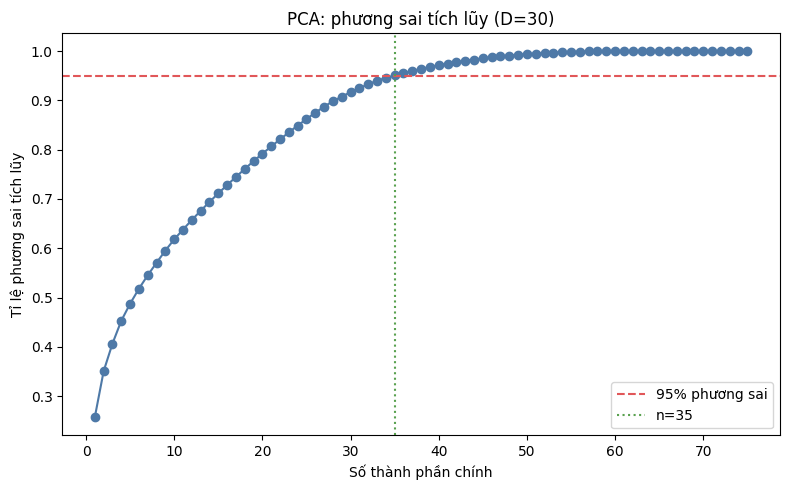

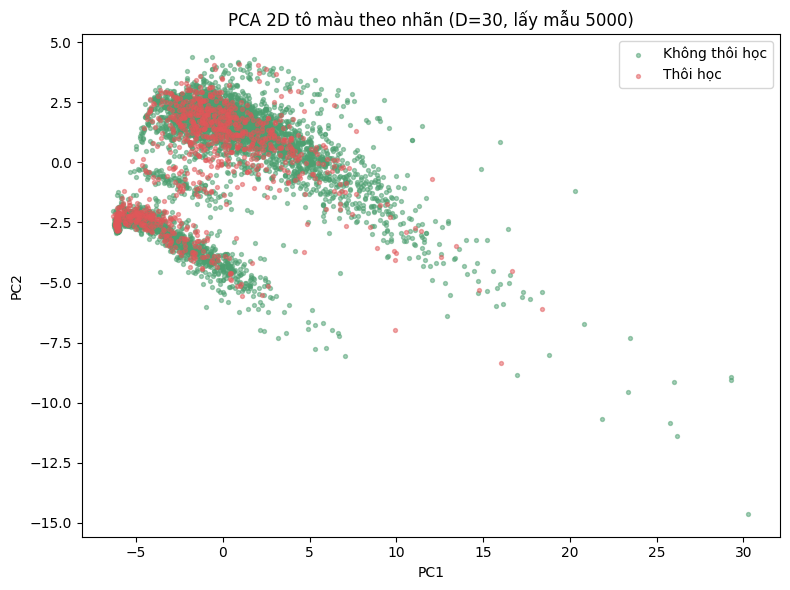

In [7]:
class ClusterAdder(BaseEstimator, TransformerMixin):
    """Thêm one-hot nhãn cụm (từ KMeans đã fit) vào ma trận đặc trưng."""
    def __init__(self, kmeans, behavior_idx, n_clusters):
        self.kmeans = kmeans; self.behavior_idx = behavior_idx; self.n_clusters = n_clusters
    def fit(self, X, y=None): return self
    def transform(self, X):
        c = self.kmeans.predict(X[:, self.behavior_idx])
        return np.hstack([X, np.eye(self.n_clusters)[c]])


def tien_xu_ly_va_tach(df, D):
    """Tách train/test theo sinh viên (cùng 1 sinh viên không nằm ở cả 2 phía), rồi tiền xử lý.
    Trả về dict để các bước sau lấy đúng thứ cần dùng."""
    X = df[COT_SO + COT_NOMINAL].copy()
    y = df["y"].values
    groups = df["id_student"].values
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    train_idx, test_idx = next(gss.split(X, y, groups=groups))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    so_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    nom_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    pre = ColumnTransformer([("so", so_pipe, COT_SO), ("nom", nom_pipe, COT_NOMINAL)])
    Xtr = pre.fit_transform(X_train); Xte = pre.transform(X_test)
    ten_nom = list(pre.named_transformers_["nom"]["onehot"].get_feature_names_out(COT_NOMINAL))
    behavior_idx = [COT_SO.index(c) for c in COT_HANH_VI]
    print(f"[D={D}] train={len(y_train)} (thôi={y_train.mean():.3f}), test={len(y_test)} "
          f"(thôi={y_test.mean():.3f}), số đặc trưng={Xtr.shape[1]}")
    return {"Xtr": Xtr, "Xte": Xte, "ytr": y_train, "yte": y_test,
            "g_tr": groups[train_idx], "pre": pre, "ten": COT_SO + ten_nom,
            "bidx": behavior_idx, "raw_tr": X_train, "raw_te": X_test}


# --- Dữ liệu tham chiếu để phân tích PCA và chọn k cho K-Means (dùng mốc triển khai) ---
ref = tien_xu_ly_va_tach(bo_du_lieu[DEPLOY_D], DEPLOY_D)
X_ref_tr, y_ref_tr, bidx_ref = ref["Xtr"], ref["ytr"], ref["bidx"]

pca_full = PCA().fit(X_ref_tr)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.searchsorted(cumvar, 0.95) + 1)
print(f"[PCA] Số thành phần giữ 95% phương sai: {n95} / {X_ref_tr.shape[1]}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(cumvar) + 1), cumvar, marker="o", color="#4E79A7")
ax.axhline(0.95, color="#E15759", linestyle="--", label="95% phương sai")
ax.axvline(n95, color="#59A14F", linestyle=":", label=f"n={n95}")
ax.set_xlabel("Số thành phần chính"); ax.set_ylabel("Tỉ lệ phương sai tích lũy")
ax.set_title(f"PCA: phương sai tích lũy (D={DEPLOY_D})"); ax.legend(); plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "pca_variance.png"), dpi=120); plt.show()

pca2 = PCA(n_components=2, random_state=SEED).fit(X_ref_tr)
Z = pca2.transform(X_ref_tr)
rng = np.random.RandomState(SEED)
idx_plot = rng.choice(len(Z), size=min(5000, len(Z)), replace=False)
fig, ax = plt.subplots(figsize=(8, 6))
for lab, col, name in [(0, "#4C9F70", "Không thôi học"), (1, "#E15759", "Thôi học")]:
    m = y_ref_tr[idx_plot] == lab
    ax.scatter(Z[idx_plot][m, 0], Z[idx_plot][m, 1], s=8, alpha=0.5, c=col, label=name)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"PCA 2D tô màu theo nhãn (D={DEPLOY_D}, lấy mẫu 5000)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(ART_DIR, "pca_2d.png"), dpi=120); plt.show()

### 4.1 Phân cụm K-Means trên đặc trưng hành vi — chọn k bằng quy tắc khuỷu tay (elbow)

[KMeans] k=2: inertia=882431
[KMeans] k=3: inertia=766215
[KMeans] k=4: inertia=720801
[KMeans] k=5: inertia=683060
[KMeans] k=6: inertia=650338
[KMeans] k=7: inertia=625070
[KMeans] k=8: inertia=596242
[KMeans] Chọn k = 3


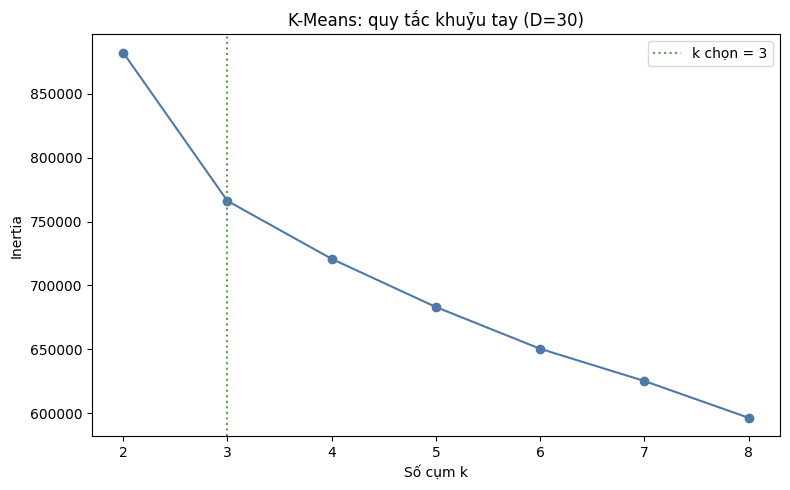

 cluster  n_students  ti_le_thoi_hoc
       0        3464           0.124
       1       12067           0.188
       2        6405           0.205


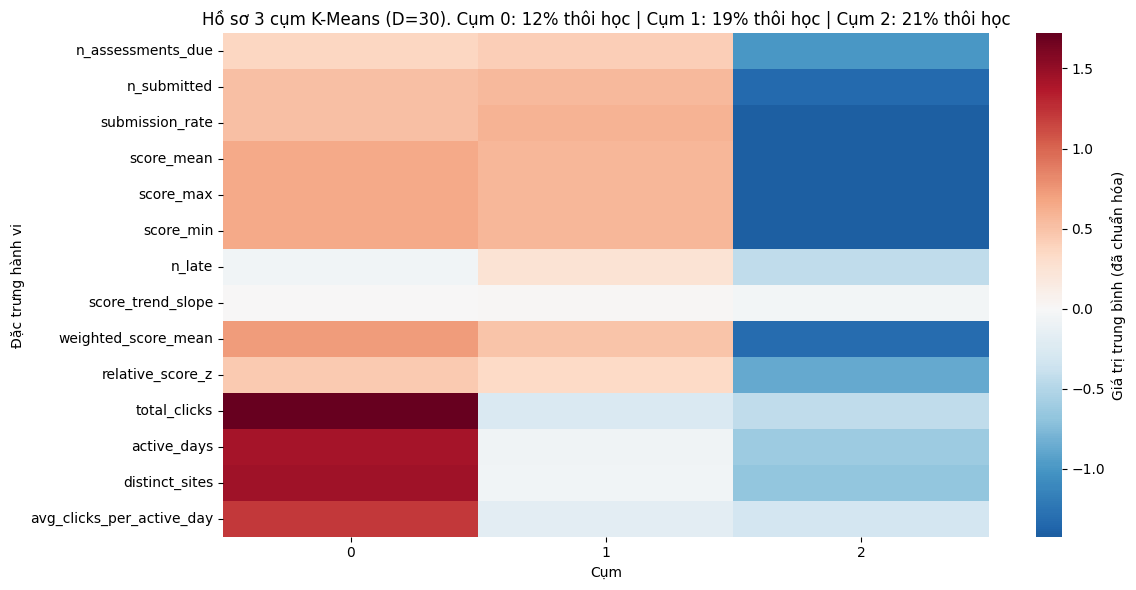

In [8]:
# K-Means trên các đặc trưng hành vi (đã chuẩn hóa ở bước tiền xử lý). Chọn k bằng quy tắc khuỷu tay (elbow).
Hv_tr = X_ref_tr[:, bidx_ref]
ks = list(range(2, 9)); inercias = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Hv_tr)
    inercias.append(km.inertia_)
    print(f"[KMeans] k={k}: inertia={km.inertia_:.0f}")

# "Khuỷu tay" = chỗ đường inertia gập mạnh nhất (sai phân bậc 2 lớn nhất)
sai_phan_2 = np.diff(inercias, n=2)
k_tot_nhat = ks[int(np.argmax(sai_phan_2)) + 1]
K_GHI_DE = None   # nhìn biểu đồ rồi muốn tự chọn k thì điền số vào đây (ví dụ 3)
if K_GHI_DE is not None:
    k_tot_nhat = K_GHI_DE
print(f"[KMeans] Chọn k = {k_tot_nhat}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ks, inercias, "o-", color="#4E79A7")
ax.axvline(k_tot_nhat, color="#59A14F", linestyle=":", label=f"k chọn = {k_tot_nhat}")
ax.set_xlabel("Số cụm k"); ax.set_ylabel("Inertia")
ax.set_title(f"K-Means: quy tắc khuỷu tay (D={DEPLOY_D})"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(ART_DIR, "kmeans_elbow.png"), dpi=120); plt.show()

km_final = KMeans(n_clusters=k_tot_nhat, random_state=SEED, n_init=10).fit(Hv_tr)
cl_tr = km_final.predict(Hv_tr)
prof = pd.DataFrame(Hv_tr, columns=COT_HANH_VI); prof["cluster"] = cl_tr; prof["y"] = y_ref_tr
profile = prof.groupby("cluster").agg(**{c: (c, "mean") for c in COT_HANH_VI},
                                      n_students=("y", "count"),
                                      ti_le_thoi_hoc=("y", "mean")).reset_index()
profile.to_csv(os.path.join(ART_DIR, "cluster_profiles.csv"), index=False)
print(profile[["cluster", "n_students", "ti_le_thoi_hoc"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6))
show_cols = [c for c in COT_HANH_VI if not c.startswith("click_")][:14]
sns.heatmap(profile.set_index("cluster")[show_cols].T, cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "Giá trị trung bình (đã chuẩn hóa)"})
ax.set_title(f"Hồ sơ {k_tot_nhat} cụm K-Means (D={DEPLOY_D}). " +
             " | ".join([f"Cụm {int(r['cluster'])}: {r['ti_le_thoi_hoc']:.0%} thôi học" for _, r in profile.iterrows()]))
ax.set_xlabel("Cụm"); ax.set_ylabel("Đặc trưng hành vi"); plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "cluster_profile.png"), dpi=120); plt.show()

## 5. Huấn luyện và đánh giá các mô hình phân lớp tại mỗi mốc D

Mô hình: Cây quyết định, KNN, Gaussian Naive Bayes, SVM tuyến tính, Rừng ngẫu nhiên, cùng 2 mô hình nền.
Tham số chọn bằng GridSearchCV (cross-validation chia theo sinh viên, tiêu chí F1) trên tập train.
Tập test chỉ dùng để báo cáo kết quả, không dùng để chọn mô hình.

In [9]:
def tinh_chi_so(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def danh_sach_mo_hinh():
    """Mỗi mô hình đi kèm lưới tham số để GridSearchCV thử (chọn bằng cross-validation trên TRAIN)."""
    return {
        "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                           {"max_depth": [4, 6, 8, 12], "min_samples_leaf": [20, 50]}),
        "KNN": (KNeighborsClassifier(),
                {"n_neighbors": [15, 31, 61]}),
        "Naive Bayes": (GaussianNB(priors=[0.5, 0.5]), {}),
        "Linear SVM": (LinearSVC(class_weight="balanced", max_iter=5000, random_state=SEED),
                           {"C": [0.01, 0.1, 1.0]}),
        "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                   random_state=SEED, n_jobs=-1),
                            {"max_depth": [8, 12], "min_samples_leaf": [10, 30]}),
    }


ket_qua = []
pipeline_rf, y_prob_rf, du_lieu_D, ten_cuoi_D = {}, {}, {}, {}

for D in DEADLINES:
    d = tien_xu_ly_va_tach(bo_du_lieu[D], D)
    Xtr, Xte, ytr, yte, bidx = d["Xtr"], d["Xte"], d["ytr"], d["yte"], d["bidx"]

    # K-Means chỉ fit trên TRAIN, rồi thêm nhãn cụm (one-hot) vào đặc trưng
    km_D = KMeans(n_clusters=k_tot_nhat, random_state=SEED, n_init=10).fit(Xtr[:, bidx])
    adder = ClusterAdder(km_D, bidx, k_tot_nhat)
    Xtr_ext, Xte_ext = adder.transform(Xtr), adder.transform(Xte)
    ten_cuoi_D[D] = d["ten"] + [f"cluster_{i}" for i in range(k_tot_nhat)]
    du_lieu_D[D] = d

    # --- 2 mô hình nền (baseline) ---
    for ten, y_pred in [("Baseline: predict all stay", np.zeros(len(yte), dtype=int)),
                        ("Baseline: predict all withdraw", np.ones(len(yte), dtype=int))]:
        ket_qua.append({"moc_D": D, "mo_hinh": ten, "loai": "nen", "cv_f1": np.nan,
                        "tham_so": "", **tinh_chi_so(yte, y_pred)})

    # --- Các mô hình: chọn tham số bằng cross-validation (chia theo sinh viên), đo trên TEST đúng 1 lần ---
    cv = GroupKFold(n_splits=CV_FOLDS)
    for ten, (md, luoi) in danh_sach_mo_hinh().items():
        gs = GridSearchCV(md, luoi, cv=cv, scoring="f1", n_jobs=(1 if ten == "Random Forest" else -1))
        gs.fit(Xtr_ext, ytr, groups=d["g_tr"])
        best = gs.best_estimator_
        y_pred = best.predict(Xte_ext)
        ket_qua.append({"moc_D": D, "mo_hinh": ten, "loai": "mo_hinh", "cv_f1": gs.best_score_,
                        "tham_so": str(gs.best_params_), **tinh_chi_so(yte, y_pred)})
        if ten == "Random Forest":
            pipeline_rf[D] = Pipeline([("pre", d["pre"]), ("cluster", adder), ("clf", best)])
            y_prob_rf[D] = best.predict_proba(Xte_ext)[:, 1]
    print(f"[D={D}] Xong {len(danh_sach_mo_hinh())} mô hình + 2 mô hình nền.")

eval_df = pd.DataFrame(ket_qua)
eval_df.to_csv(os.path.join(ART_DIR, "evaluation_results.csv"), index=False)
cot_in = ["moc_D", "mo_hinh", "cv_f1", "accuracy", "precision", "recall", "f1"]
print(eval_df[cot_in].sort_values(["moc_D", "f1"], ascending=[True, False]).round(3).to_string(index=False))

# Xếp hạng bằng cross-validation (không nhìn tập test) tại mốc triển khai
xh = (eval_df[(eval_df.moc_D == DEPLOY_D) & (eval_df.loai == "mo_hinh")]
      .sort_values("cv_f1", ascending=False)[["mo_hinh", "cv_f1", "f1"]])
print(f"\n[Xếp hạng theo cv_f1 tại D={DEPLOY_D}]"); print(xh.round(3).to_string(index=False))

[D=30] train=21936 (thôi=0.183), test=5507 (thôi=0.184), số đặc trưng=75
[D=30] Xong 5 mô hình + 2 mô hình nền.
[D=60] train=21035 (thôi=0.150), test=5311 (thôi=0.147), số đặc trưng=75
[D=60] Xong 5 mô hình + 2 mô hình nền.
[D=90] train=20439 (thôi=0.120), test=5112 (thôi=0.132), số đặc trưng=75
[D=90] Xong 5 mô hình + 2 mô hình nền.
 moc_D                     mo_hinh  cv_f1  accuracy  precision  recall    f1
    30              SVM tuyến tính  0.409     0.686      0.320   0.627 0.424
    30             Rừng ngẫu nhiên  0.403     0.722      0.341   0.546 0.420
    30              Cây quyết định  0.383     0.648      0.289   0.623 0.395
    30                 Naive Bayes  0.332     0.370      0.207   0.855 0.333
    30   Nền: đoán tất cả thôi học    NaN     0.184      0.184   1.000 0.311
    30                         KNN  0.142     0.820      0.562   0.099 0.168
    30 Nền: đoán không ai thôi học    NaN     0.816      0.000   0.000 0.000
    60              SVM tuyến tính  0.381     0.

## 6. Trực quan hóa: so sánh F1, ma trận nhầm lẫn, độ quan trọng đặc trưng, mức rủi ro

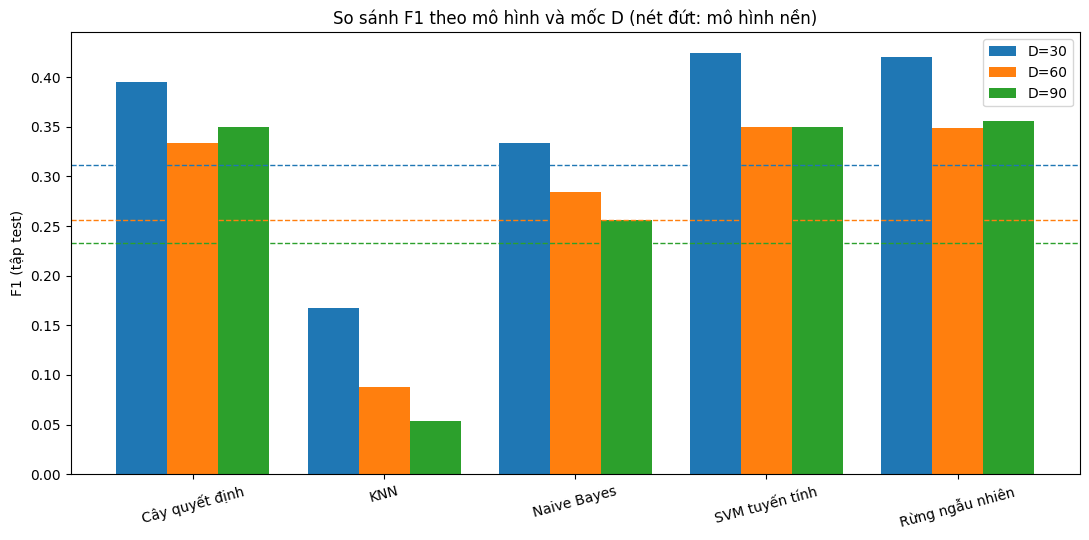

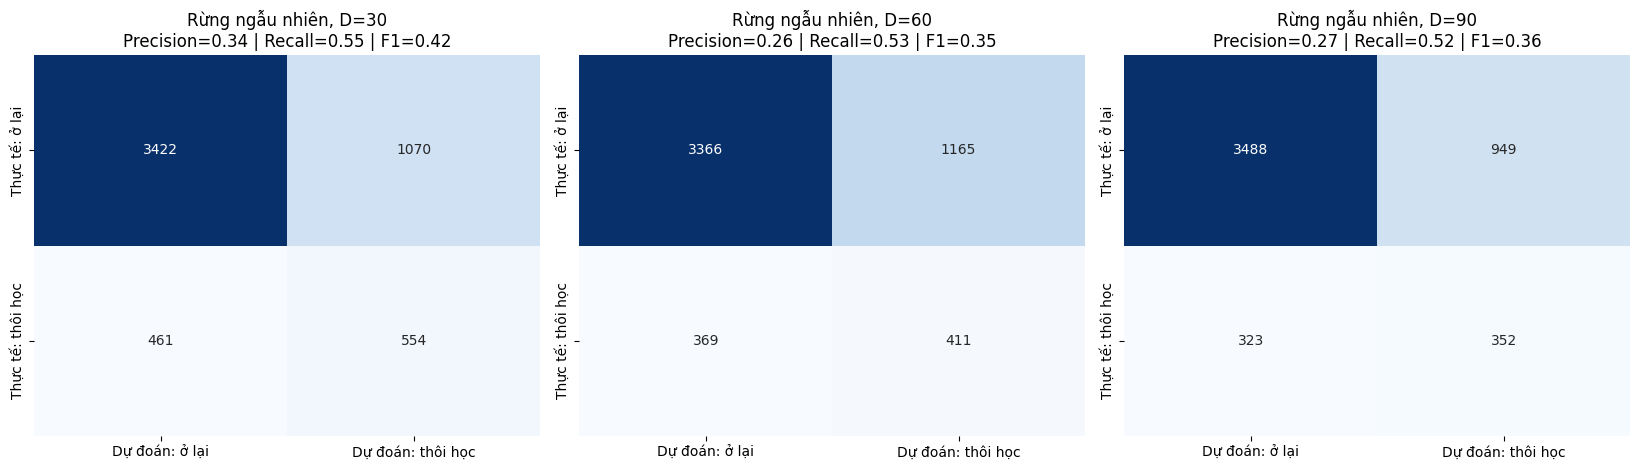

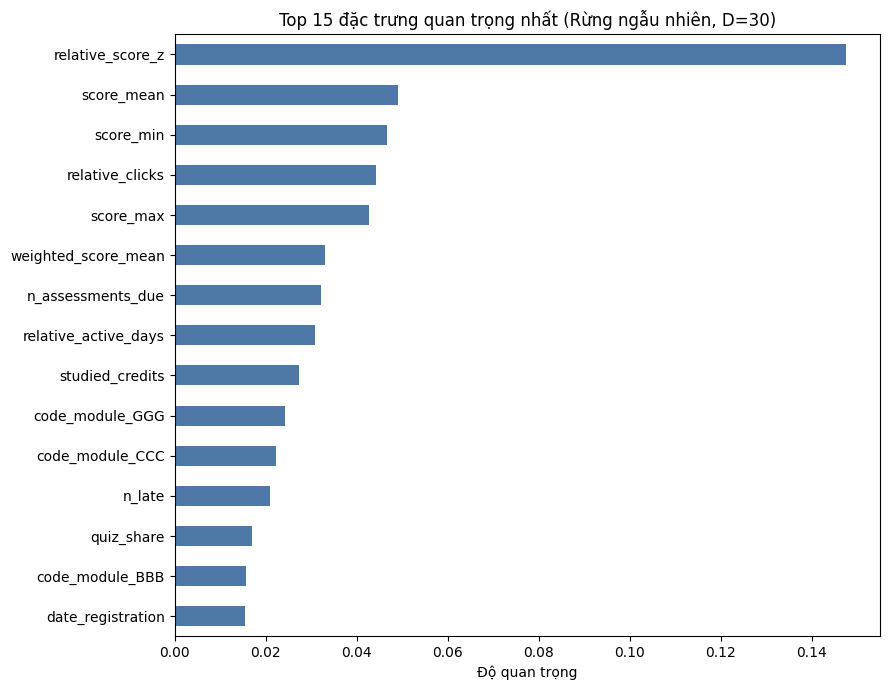

[Mức rủi ro Thấp      ]  3855 sinh viên | thực tế thôi học: 11.8%
[Mức rủi ro Trung bình]  1101 sinh viên | thực tế thôi học: 27.2%
[Mức rủi ro Cao       ]   551 sinh viên | thực tế thôi học: 47.4%
Ngưỡng xác suất: Trung bình từ 0.498, Cao từ 0.667 | tỉ lệ thôi học chung: 18.4%


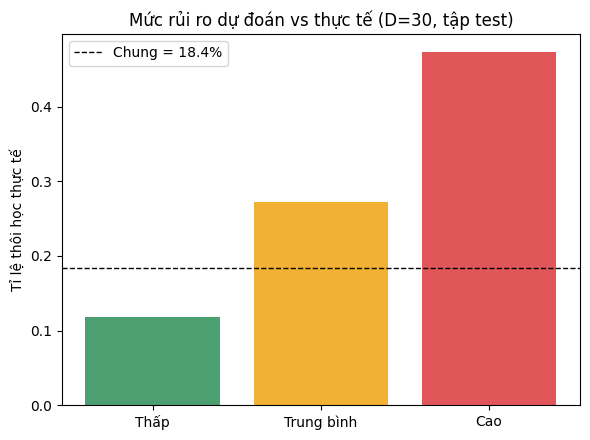

In [10]:
mh = eval_df[eval_df.loai == "mo_hinh"]
ten_mh = list(mh.mo_hinh.unique())

# --- 1. F1 trên tập test của từng mô hình theo mốc D (đường nét đứt = mô hình nền "đoán tất cả thôi học") ---
fig, ax = plt.subplots(figsize=(11, 5.5))
rong = 0.8 / len(DEADLINES); x = np.arange(len(ten_mh))
for j, D in enumerate(DEADLINES):
    sub = mh[mh.moc_D == D].set_index("mo_hinh").loc[ten_mh]
    ax.bar(x + j * rong, sub["f1"].values, width=rong, color=f"C{j}", label=f"D={D}")
    f1_nen = eval_df[(eval_df.moc_D == D) & (eval_df.mo_hinh == "Baseline: predict all withdraw")]["f1"].iloc[0]
    ax.axhline(f1_nen, color=f"C{j}", linestyle="--", lw=1)
ax.set_xticks(x + rong); ax.set_xticklabels(ten_mh, rotation=15)
ax.set_ylabel("F1 (tập test)"); ax.set_title("So sánh F1 theo mô hình và mốc D (nét đứt: mô hình nền)")
ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(ART_DIR, "so_sanh_f1.png"), dpi=120); plt.show()

# --- 2. Ma trận nhầm lẫn của Random Forest ---
fig, axes = plt.subplots(1, len(DEADLINES), figsize=(5.5 * len(DEADLINES), 4.8))
for ax, D in zip(np.atleast_1d(axes), DEADLINES):
    r = eval_df[(eval_df.moc_D == D) & (eval_df.mo_hinh == "Random Forest")].iloc[0]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]]).astype(int)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["Dự đoán: ở lại", "Dự đoán: thôi học"], yticklabels=["Thực tế: ở lại", "Thực tế: thôi học"])
    ax.set_title(f"Random Forest, D={D}\nPrecision={r.precision:.2f} | Recall={r.recall:.2f} | F1={r.f1:.2f}")
plt.tight_layout(); plt.savefig(os.path.join(ART_DIR, "confusion_matrices.png"), dpi=120); plt.show()

# --- 3. Độ quan trọng đặc trưng của đúng mô hình triển khai (Random Forest, D=DEPLOY_D) ---
rf_dep = pipeline_rf[DEPLOY_D].named_steps["clf"]
imp = pd.Series(rf_dep.feature_importances_, index=ten_cuoi_D[DEPLOY_D]).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 7))
imp.head(15)[::-1].plot(kind="barh", ax=ax, color="#4E79A7")
ax.set_title(f"Top 15 đặc trưng quan trọng nhất (Random Forest, D={DEPLOY_D})")
ax.set_xlabel("Độ quan trọng"); plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "feature_importance.png"), dpi=120); plt.show()
top10 = imp.head(10).to_dict()

# --- 4. Mức rủi ro: chia sinh viên test theo xác suất rồi xem tỉ lệ thôi học THỰC TẾ của từng nhóm ---
p_te, y_te = y_prob_rf[DEPLOY_D], du_lieu_D[DEPLOY_D]["yte"]
nguong_tb, nguong_cao = [float(v) for v in np.quantile(p_te, PHAN_VI)]
nhom = np.where(p_te >= nguong_cao, "Cao", np.where(p_te >= nguong_tb, "Trung bình", "Thấp"))
ban_rui_ro = {}
for ten in ["Thấp", "Trung bình", "Cao"]:
    m = nhom == ten
    ban_rui_ro[ten] = {"n": int(m.sum()), "ti_le_thoi_hoc": float(y_te[m].mean())}
    print(f"[Mức rủi ro {ten:<10}] {m.sum():>5} sinh viên | thực tế thôi học: {y_te[m].mean():.1%}")
print(f"Ngưỡng xác suất: Trung bình từ {nguong_tb:.3f}, Cao từ {nguong_cao:.3f} | tỉ lệ thôi học chung: {y_te.mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(list(ban_rui_ro), [v["ti_le_thoi_hoc"] for v in ban_rui_ro.values()], color=["#4C9F70", "#F2B134", "#E15759"])
ax.axhline(y_te.mean(), color="k", linestyle="--", lw=1, label=f"Chung = {y_te.mean():.1%}")
ax.set_ylabel("Tỉ lệ thôi học thực tế"); ax.set_title(f"Mức rủi ro dự đoán vs thực tế (D={DEPLOY_D}, tập test)")
ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(ART_DIR, "phan_vi_rui_ro.png"), dpi=120); plt.show()

## 7. Lưu mô hình và tóm tắt kết quả

In [ ]:
# Tài liệu tham khảo: chỉ giữ những nguồn đã kiểm chứng. Hãy tự mở link và bổ sung nguồn khác sau khi đọc.
BENCHMARKS = [
    {"nguon": "Kuzilek, Hlosta, Zdrahal 2017 — bài báo gốc của bộ dữ liệu OULAD",
     "url": "https://www.nature.com/articles/sdata2017171",
     "chi_so": "32.593 lượt đăng ký, 22 module-presentation, khoảng 10 triệu tương tác trên VLE"},
    {"nguon": "Frontiers in Education 2024 — Analyzing click data with AI",
     "url": "https://www.frontiersin.org/journals/education/articles/10.3389/feduc.2024.1421479/full",
     "chi_so": "Random Forest accuracy ≈ 78,68% (định nghĩa bài toán khác, không so sánh trực tiếp được)"},
]
with open(os.path.join(ART_DIR, "benchmarks.json"), "w", encoding="utf-8") as f:
    json.dump(BENCHMARKS, f, ensure_ascii=False, indent=2)

pipe = pipeline_rf[DEPLOY_D]
d = du_lieu_D[DEPLOY_D]
joblib.dump(pipe, os.path.join(ART_DIR, "best_model.joblib"))
joblib.dump(d["pre"], os.path.join(ART_DIR, "preprocessor.joblib"))
joblib.dump(pipe.named_steps["cluster"].kmeans, os.path.join(ART_DIR, "kmeans.joblib"))
with open(os.path.join(ART_DIR, "feature_names.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(ten_cuoi_D[DEPLOY_D]))

# Giá trị mặc định THẬT (trung vị của tập train) cho giao diện, thay cho các số tự ước lượng trước đây
mac_dinh = {c: float(v) for c, v in d["raw_tr"][COT_SO].apply(pd.to_numeric, errors="coerce").median().items()}
mac_dinh.update({c: str(d["raw_tr"][c].mode().iloc[0]) for c in COT_NOMINAL})
with open(os.path.join(ART_DIR, "defaults_median.json"), "w", encoding="utf-8") as f:
    json.dump(mac_dinh, f, ensure_ascii=False, indent=2)

# 300 sinh viên THẬT từ tập test để giao diện cho chọn rồi chỉnh sửa
mau = d["raw_te"].copy(); mau["y_thuc_te"] = d["yte"]
mau.sample(n=min(300, len(mau)), random_state=SEED).to_csv(
    os.path.join(ART_DIR, "sample_students.csv"), index=False)

with open(os.path.join(ART_DIR, "requirements.txt"), "w") as f:
    f.write("pandas\nnumpy\nscikit-learn\nmatplotlib\nseaborn\njoblib\nstreamlit\n")

dac_trung_nang_cao = COT_VLE_NANG_CAO + COT_INTERACT + ["score_trend_slope", "weighted_score_mean",
                                                        "relative_score_z", "late_registration",
                                                        "relative_clicks", "relative_active_days"]
importance_nang_cao = {k: float(imp.get(k, 0.0)) for k in dac_trung_nang_cao}

rf_dep_row = eval_df[(eval_df.moc_D == DEPLOY_D) & (eval_df.mo_hinh == "Random Forest")].iloc[0]
nen_row = eval_df[(eval_df.moc_D == DEPLOY_D) & (eval_df.mo_hinh == "Baseline: predict all withdraw")].iloc[0]
summary = {
    "best_model": "Random Forest", "best_deadline_D": int(DEPLOY_D),
    "accuracy": float(rf_dep_row.accuracy), "precision": float(rf_dep_row.precision),
    "recall": float(rf_dep_row.recall), "best_f1": float(rf_dep_row.f1),
    "cv_f1": float(rf_dep_row.cv_f1), "f1_nen_doan_tat_ca_thoi_hoc": float(nen_row.f1),
    "metrics_rf_per_D": {str(D): eval_df[(eval_df.moc_D == D) & (eval_df.mo_hinh == "Random Forest")][
        ["accuracy", "precision", "recall", "f1", "cv_f1"]].iloc[0].astype(float).to_dict() for D in DEADLINES},
    "risk_bands": {"nguong_trung_binh": nguong_tb, "nguong_cao": nguong_cao,
                   "phan_vi": list(PHAN_VI), "ket_qua": ban_rui_ro,
                   "ti_le_thoi_hoc_chung": float(y_te.mean())},
    "top10_features": top10,
    "advanced_features_importance": importance_nang_cao,
    "benchmarks": BENCHMARKS,
    "class_counts_per_D": {str(D): {"0": int((bo_du_lieu[D].y == 0).sum()),
                                    "1": int((bo_du_lieu[D].y == 1).sum())} for D in DEADLINES},
    "dataset_size_per_D": {str(D): int(len(bo_du_lieu[D])) for D in DEADLINES},
    "n_clusters_kmeans": int(k_tot_nhat), "pca_n_components_95pct": int(n95),
    "notes": ("Cửa sổ studentVle [0,90]; tách train/test theo id_student; tham số chọn bằng GridSearchCV "
              "(GroupKFold theo sinh viên, tiêu chí F1) trên tập train, tập test chỉ dùng để báo cáo; "
              "class_weight='balanced' (Cây, SVM, Rừng), priors 50/50 (Naive Bayes); "
              "K-Means chọn k bằng quy tắc khuỷu tay; không dùng deep learning."),
}
with open(os.path.join(ART_DIR, "summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(f"[OK] Mô hình triển khai: Random Forest, D={DEPLOY_D} | "
      f"F1={rf_dep_row.f1:.3f} (nền {nen_row.f1:.3f}), Precision={rf_dep_row.precision:.3f}, Recall={rf_dep_row.recall:.3f}")
print("[HOÀN TẤT] Tất cả kết quả đã được lưu tại", ART_DIR)

## 8. Nguồn tham khảo

1. OULAD dataset (UCI): https://archive.ics.uci.edu/dataset/349/open+university+learning+analytics+dataset
2. Kuzilek, Hlosta, Zdrahal (2017), Scientific Data: https://www.nature.com/articles/sdata2017171
3. Frontiers in Education 2024 (click data, RF 78,68%): https://www.frontiersin.org/journals/education/articles/10.3389/feduc.2024.1421479/full

*(Các nguồn khác từng có trong bản cũ chưa được kiểm chứng. Chỉ thêm lại sau khi tự mở link và đọc.)*